# Generate images

In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler



# Control NaN values
df = pd.read_csv("dataset_nuevo_corregido.csv").drop(columns = ['Risk', 'Risk_Label'], axis = 1)

df.replace([np.inf, -np.inf], np.nan, inplace=True)  # Replace infinity with NaN
df.fillna(df.max(), inplace=True)
scaler = MinMaxScaler()
df_scaled = pd.DataFrame(scaler.fit_transform(df), columns=df.columns)


In [2]:
import os
import numpy as np
from scipy.stats import pearsonr

# Check if the file exists
if os.path.exists('vfp/sorted_indices_vfp.txt'):
    # Read the sorted indices from the file
    with open('vfp/sorted_indices_vfp.txt', 'r') as file:
        sorted_indices_desc = np.array([int(line.strip()) for line in file.readlines()])
else:
    # Step 1 & 2: Calculate PCCs and sum them for each attribute
    pcc_sums = np.array([sum([pearsonr(df[col], df[other_col])[0] for other_col in df.columns if other_col != col]) for col in df.columns])

    # Step 3: Sort attributes by PCC sums
    sorted_indices_asc = np.argsort(pcc_sums)
    sorted_indices_desc = sorted_indices_asc[::-1]  # Assuming combined_features_sorted is this

    # Ensure the directory exists
    os.makedirs('vfp', exist_ok=True)
    # Write the sorted indices to the file
    with open('vfp/sorted_indices_vfp.txt', 'w') as file:
        for index in sorted_indices_desc:
            file.write(f"{index}\n")

In [3]:
import numpy as np

def arrange_in_vortex(row, indices, image_size):
    # Create an empty matrix for the single-channel image
    image = np.zeros((image_size, image_size))
    # Adjusting for a counterclockwise spiral starting from the center
    center = image_size // 2
    x, y = center, center
    dx, dy = 0, -1  # Adjust initial direction for counterclockwise spiral
    step_size = 1
    steps_count = 0
    change_direction_steps = 1
    direction_changes = 0  # Track the number of direction changes

    for i in range(len(indices)):
        # Check if the current position is within bounds
        if 0 <= x < image_size and 0 <= y < image_size:
            # Access the row by column index
            image[x, y] = row.iloc[indices[i]] * 255
        steps_count += 1
        if steps_count == change_direction_steps:
            steps_count = 0
            direction_changes += 1
            # Change direction
            dx, dy = -dy, dx
            # Increase step size after every two direction changes
            if direction_changes % 2 == 0:
                change_direction_steps += 1

        x, y = x + dx, y + dy

    return image


Index: 0


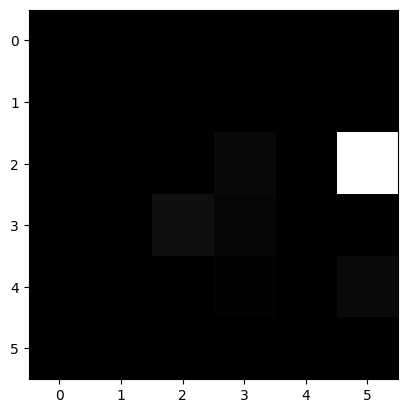

Index: 40000


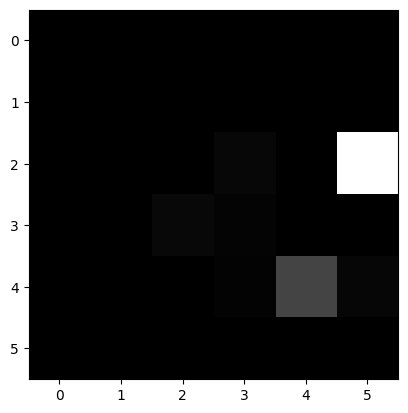

Index: 80000


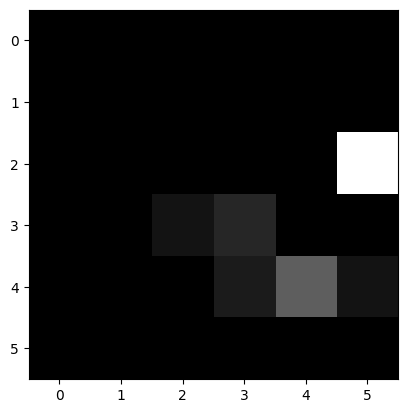

In [4]:

import numpy as np
import pandas as pd
from scipy.stats import pearsonr
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler



# Step 4: Generate images and print index and image if index % 40 is 0
image_size = 6  # Example size, adjust as needed
images = [] 
for index, row in df.iterrows():
    image = arrange_in_vortex(row, sorted_indices_desc, image_size)
    images.append(image)
    if index % 40000 == 0:
        print(f"Index: {index}")
        plt.imshow(image, cmap='gray')
        plt.show()

images = np.array(images)

# Step 5: Replicate the single-channel images across three channels
images_rgb = np.repeat(images[..., np.newaxis], 3, -1)

# Normalize images
scaler = MinMaxScaler()
images_rgb = scaler.fit_transform(images_rgb.reshape(-1, images_rgb.shape[-1])).reshape(images_rgb.shape)

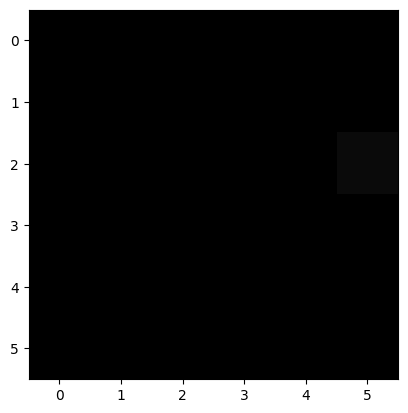

In [5]:

# Example: Show the first image
plt.imshow(images_rgb[0], cmap='gray')
plt.show()

In [6]:
images_rgb[0].shape

(6, 6, 3)

In [7]:
df2 = pd.read_csv("dataset_nuevo_corregido.csv")

# Run training

## Fitting a CNN Model

In [8]:
import torch
import torch.nn as nn
import torchvision.transforms as transforms
from torch.utils.data import TensorDataset, DataLoader
import torch.optim as optim
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay
import torch.nn.functional as F

In [9]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=8):
        super(SimpleCNN, self).__init__()
        self.conv1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.pool = nn.MaxPool2d(2, 2)  # Output size: 16x15x15
        self.dropout1 = nn.Dropout(0.25)  # Dropout added for regularization
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)  # Output size: 32x7x7
        self.dropout2 = nn.Dropout(0.25)  # Another dropout layer for regularization
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.dropout1(x)
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.dropout2(x)
        # Dynamically calculate the correct size
        size = x.size(1) * x.size(2) * x.size(3)
        x = x.view(x.size(0), -1)
        if self.fc1.in_features != size:
            self.fc1 = nn.Linear(size, 128).to(x.device)  # Adjust the layer dynamically
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x

'''
    def forward(self, x):
        x = self.pool(torch.relu(self.conv1(x)))
        x = self.dropout1(x)
        x = self.pool(torch.relu(self.conv2(x)))
        x = self.dropout2(x)
        x = x.view(x.size(0), -1)
        x = torch.relu(self.fc1(x))
        x = self.fc2(x)
        return x
'''

'\n    def forward(self, x):\n        x = self.pool(torch.relu(self.conv1(x)))\n        x = self.dropout1(x)\n        x = self.pool(torch.relu(self.conv2(x)))\n        x = self.dropout2(x)\n        x = x.view(x.size(0), -1)\n        x = torch.relu(self.fc1(x))\n        x = self.fc2(x)\n        return x\n'

In [10]:
import numpy as np
from sklearn.model_selection import train_test_split

y = df2["Risk_Label"]
 
X_train, X_test, y_train, y_test = train_test_split(images_rgb, y, test_size=0.2, random_state=42)

In [11]:
from sklearn.preprocessing import LabelEncoder
from collections import Counter
# from sklearn.model_selection import train_test_split
import numpy as np

#y = df["Label"]
# Add stratify=y to ensure the same distribution of classes in both sets
#X_train, X_test, y_train, y_test = train_test_split(X_REFINED_MDS, y, test_size=0.2, random_state=42, stratify=y)

#y_train = y_train.values
#y_test = y_test.values

le = LabelEncoder()
y_train_enc = le.fit_transform(y_train)
y_test_enc = le.transform(y_test)
num_classes = np.unique(y_train_enc).size

print(Counter(y_train_enc))
print(Counter(y_test_enc))

Counter({3: 38468, 1: 21894, 2: 13854, 4: 6003, 0: 18})
Counter({3: 9792, 1: 5346, 2: 3464, 4: 1454, 0: 4})


In [12]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)
preprocess = transforms.Compose([
    transforms.ToTensor()
])
X_train_tensor = torch.tensor(X_train[:,:,:,0], dtype=torch.float).unsqueeze(1)  # Selects the first channel and adds a channel dimension
y_train_tensor = torch.from_numpy(le.fit_transform(y_train))

X_test_tensor = torch.tensor(X_test[:,:,:,0], dtype=torch.float).unsqueeze(1)  # Selects the first channel and adds a channel dimension
y_test_tensor = torch.from_numpy(le.transform(y_test))

cuda


In [13]:
batch_size = 32

trainset = TensorDataset(X_train_tensor, y_train_tensor)
trainloader = DataLoader(trainset, batch_size=batch_size, shuffle=True)

testset = TensorDataset(X_test_tensor, y_test_tensor)
testloader = DataLoader(testset, batch_size=batch_size, shuffle=False)

In [14]:
model = SimpleCNN(num_classes=num_classes).to(device)
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(
    model.parameters(),
    lr=1e-03,
    weight_decay=1e-05
)

In [15]:
model.train()
model.to(device)
for epoch in range(100):

    running_loss = 0.0
    for i, data in enumerate(trainloader, 0):
        # get the inputs; data is a list of [inputs, labels]
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device).long()

        outputs = model(inputs)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        running_loss += loss.item()
    # print epoch statistics
    if not (epoch % 20):
        print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')
print(f'[{epoch}] loss: {running_loss / len(X_train_tensor) * batch_size:.3f}')

[0] loss: 0.909
[20] loss: 0.146
[40] loss: 0.115
[60] loss: 0.096
[80] loss: 0.086
[99] loss: 0.081


In [16]:
model.to('cpu')
model = model.eval()
with torch.no_grad():
    y_hat = model(X_train_tensor)
train_predicted = torch.max(y_hat, 1)[1]
with torch.no_grad():
    y_hat = model(X_test_tensor)
test_predicted = torch.max(y_hat, 1)[1]
print(f"The train accuracy was {accuracy_score(train_predicted, y_train_tensor):.3f}")
print(f"The test accuracy was {accuracy_score(test_predicted, y_test_tensor):.3f}")

The train accuracy was 0.981
The test accuracy was 0.982


In [17]:
from sklearn.metrics import f1_score, recall_score

# Calculate F1 score
f1 = f1_score(y_test_tensor, test_predicted, average='weighted')  # Use 'binary' for binary classification, 'weighted' for multi-class

# Calculate Recall
recall = recall_score(y_test_tensor, test_predicted, average='weighted')  # Use 'binary' for binary classification, 'weighted' for multi-class

print(f"F1 Score: {f1}")
print(f"Recall: {recall}")

F1 Score: 0.9815530109166615
Recall: 0.981655034895314


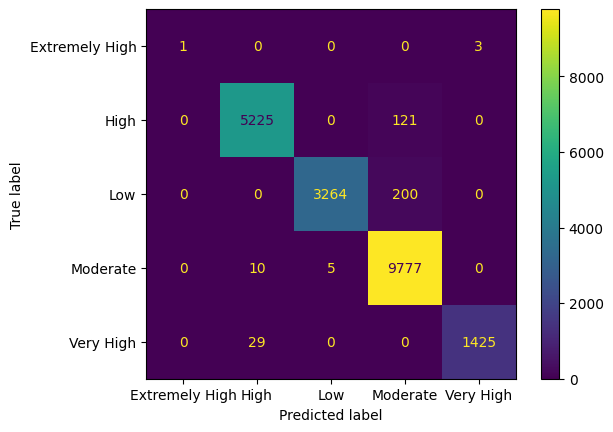

In [18]:
_ = ConfusionMatrixDisplay.from_predictions(y_test_tensor, test_predicted, display_labels=le.classes_)